Load your preprocessed data

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("../../data/processed/leptospirosis_2008_2024.csv")

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values(["District", "Date"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Number of districts:", df["District"].nunique())

display(df.head())


Dataset shape: (5100, 15)
Date range: 2008-01-01 00:00:00 to 2024-12-01 00:00:00
Number of districts: 25


,District,Year,Month,Cases,YearMonth,Precipitation_mm,Temp_Min_C,Temp_Max_C,Soil_Moisture_0_7cm,MRiceArea,MRiceYield,SRiceArea,SRiceYield,Population,Date
0,Ampara,2008,1,1,2008-01,177.600000,19.8505,29.6005,0.380341,64490.0,4864.0,60168.0,4927.0,620469,2008-01-01
1,Ampara,2008,2,3,2008-02,121.000000,18.9005,28.9005,0.362213,64490.0,4864.0,60168.0,4927.0,620469,2008-02-01
2,Ampara,2008,3,0,2008-03,293.600000,21.8005,30.7505,0.385442,64490.0,4864.0,60168.0,4927.0,620469,2008-03-01
3,Ampara,2008,4,1,2008-04,119.000010,23.0505,32.5505,0.359476,64490.0,4864.0,60168.0,4927.0,620469,2008-04-01
4,Ampara,2008,5,4,2008-05,34.600002,24.3005,34.5505,0.269909,64490.0,4864.0,60168.0,4927.0,620469,2008-05-01


Check data quality before analysis

In [5]:

# Missing-value summary
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

display(missing_summary.sort_values(
    "Missing_Percentage", ascending=False
))

# Check whether every district has 204 months
coverage = df.groupby("District")["Date"].nunique()

print("Districts with incomplete coverage:")
display(coverage[coverage != 204])

print("Duplicate district-month records:",
      df.duplicated(["District", "Date"]).sum())

print("Negative case counts:", (df["Cases"] < 0).sum())


,Missing_Count,Missing_Percentage
SRiceYield,348,6.82
SRiceArea,348,6.82
MRiceYield,36,0.71
MRiceArea,36,0.71
District,0,0.00
Year,0,0.00
Month,0,0.00
Temp_Min_C,0,0.00
Precipitation_mm,0,0.00
YearMonth,0,0.00


Districts with incomplete coverage:


Series([], Name: Date, dtype: int64)

Duplicate district-month records: 0
Negative case counts: 0


Visualize the overall leptospirosis trend

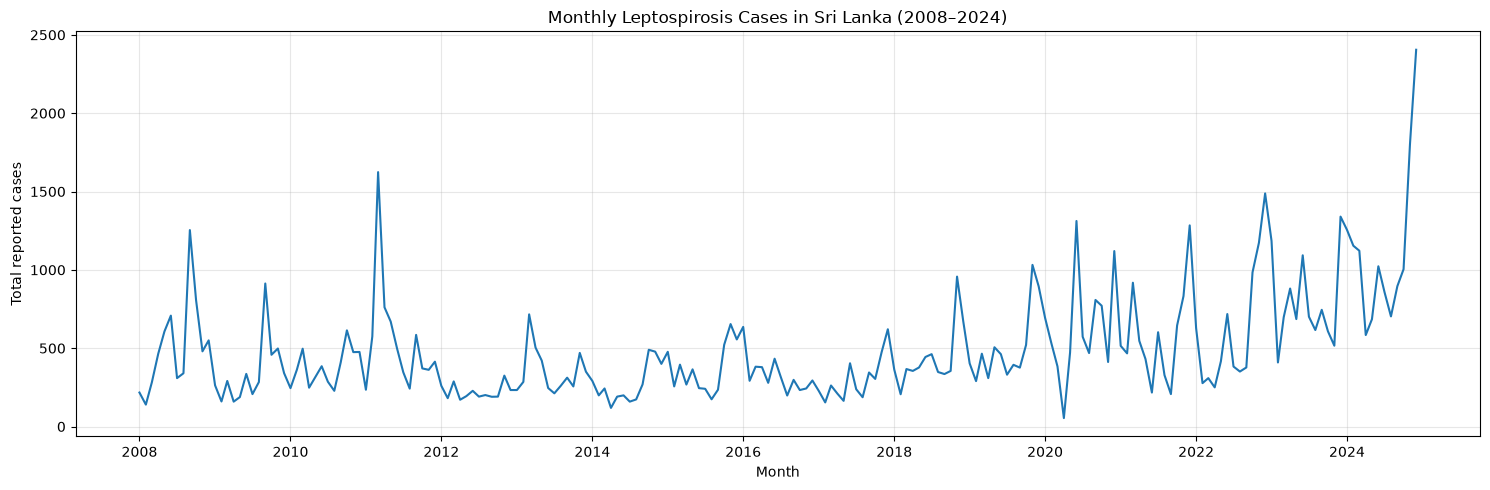

In [6]:

monthly_cases = (
    df.groupby("Date", as_index=False)
      .agg(Total_Cases=("Cases", "sum"))
      .sort_values("Date")
)

plt.figure(figsize=(15, 5))
plt.plot(
    monthly_cases["Date"],
    monthly_cases["Total_Cases"]
)
plt.title("Monthly Leptospirosis Cases in Sri Lanka (2008–2024)")
plt.xlabel("Month")
plt.ylabel("Total reported cases")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Compare total cases across districts

,District,Total_Cases,Mean_Monthly_Cases,Maximum_Monthly_Cases
22,Ratnapura,12981,63.632353,377
9,Kalutara,9921,48.632353,215
4,Colombo,9549,46.808824,859
5,Galle,8306,40.715686,247
11,Kegalle,7603,37.269608,202
13,Kurunegala,7589,37.200980,745
6,Gampaha,7459,36.563725,430
16,Matara,5869,28.769608,147
1,Anuradhapura,4033,19.769608,113
17,Monaragala,4012,19.666667,140


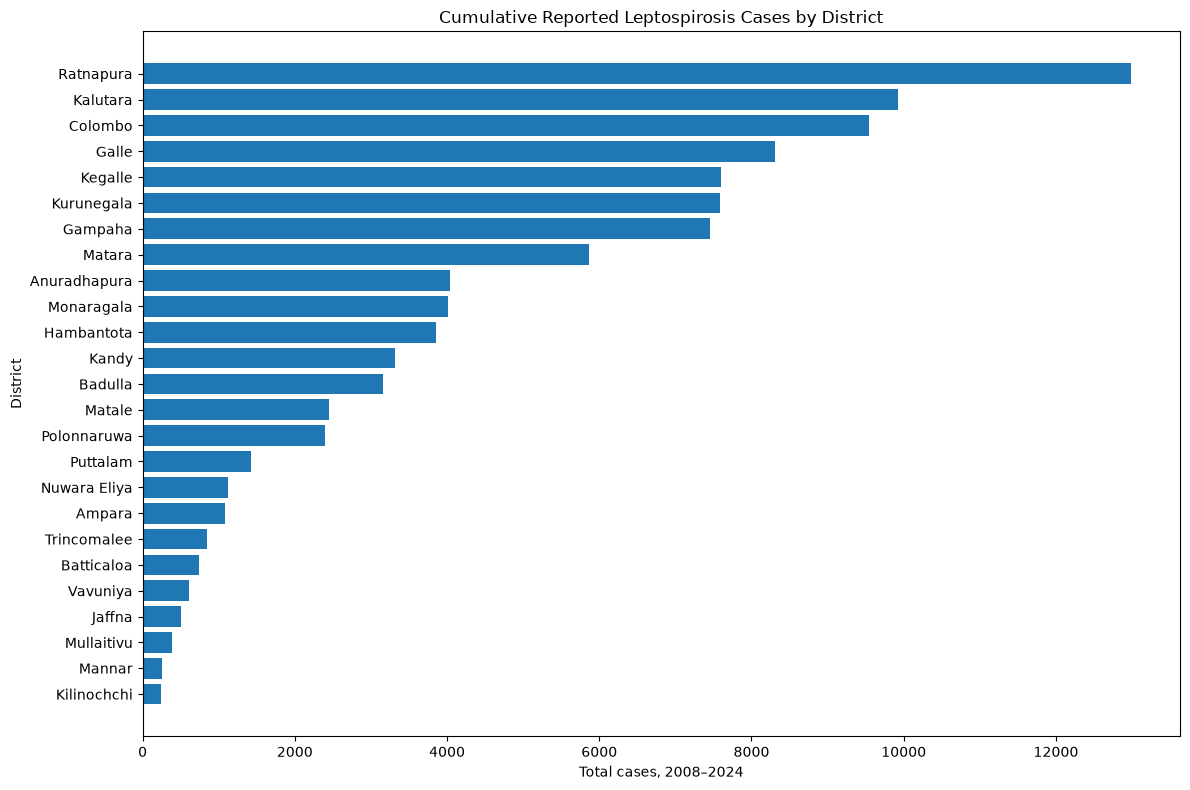

In [7]:

district_cases = (
    df.groupby("District", as_index=False)
      .agg(
          Total_Cases=("Cases", "sum"),
          Mean_Monthly_Cases=("Cases", "mean"),
          Maximum_Monthly_Cases=("Cases", "max")
      )
      .sort_values("Total_Cases", ascending=False)
)

display(district_cases)

plt.figure(figsize=(12, 8))
plt.barh(
    district_cases["District"][::-1],
    district_cases["Total_Cases"][::-1]
)
plt.title("Cumulative Reported Leptospirosis Cases by District")
plt.xlabel("Total cases, 2008–2024")
plt.ylabel("District")
plt.tight_layout()
plt.show()


Investigate seasonality

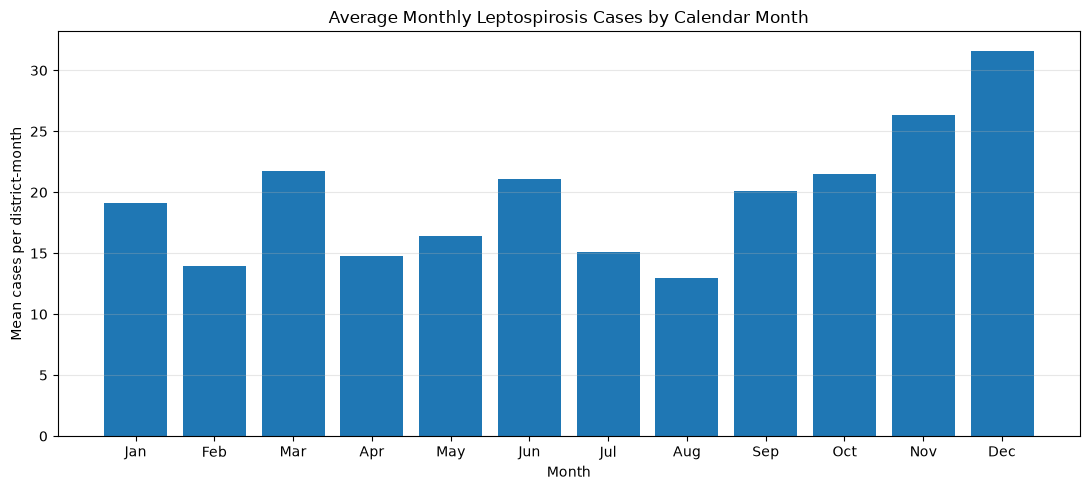

,Month_Number,Mean_Cases,Median_Cases,Maximum_Cases
0,1,19.127059,10.0,430
1,2,13.969412,7.0,260
2,3,21.748235,9.0,745
3,4,14.738824,6.0,152
4,5,16.400000,8.0,175
5,6,21.058824,10.0,377
6,7,15.091765,7.0,153
7,8,12.931765,6.0,142
8,9,20.127059,6.0,465
9,10,21.491765,6.0,542


In [8]:

df["Month_Number"] = df["Date"].dt.month

seasonal_cases = (
    df.groupby("Month_Number", as_index=False)
      .agg(
          Mean_Cases=("Cases", "mean"),
          Median_Cases=("Cases", "median"),
          Maximum_Cases=("Cases", "max")
      )
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(11, 5))
plt.bar(
    seasonal_cases["Month_Number"],
    seasonal_cases["Mean_Cases"]
)
plt.xticks(range(1, 13), month_names)
plt.title("Average Monthly Leptospirosis Cases by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Mean cases per district-month")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(seasonal_cases)


Create a district-by-month heatmap

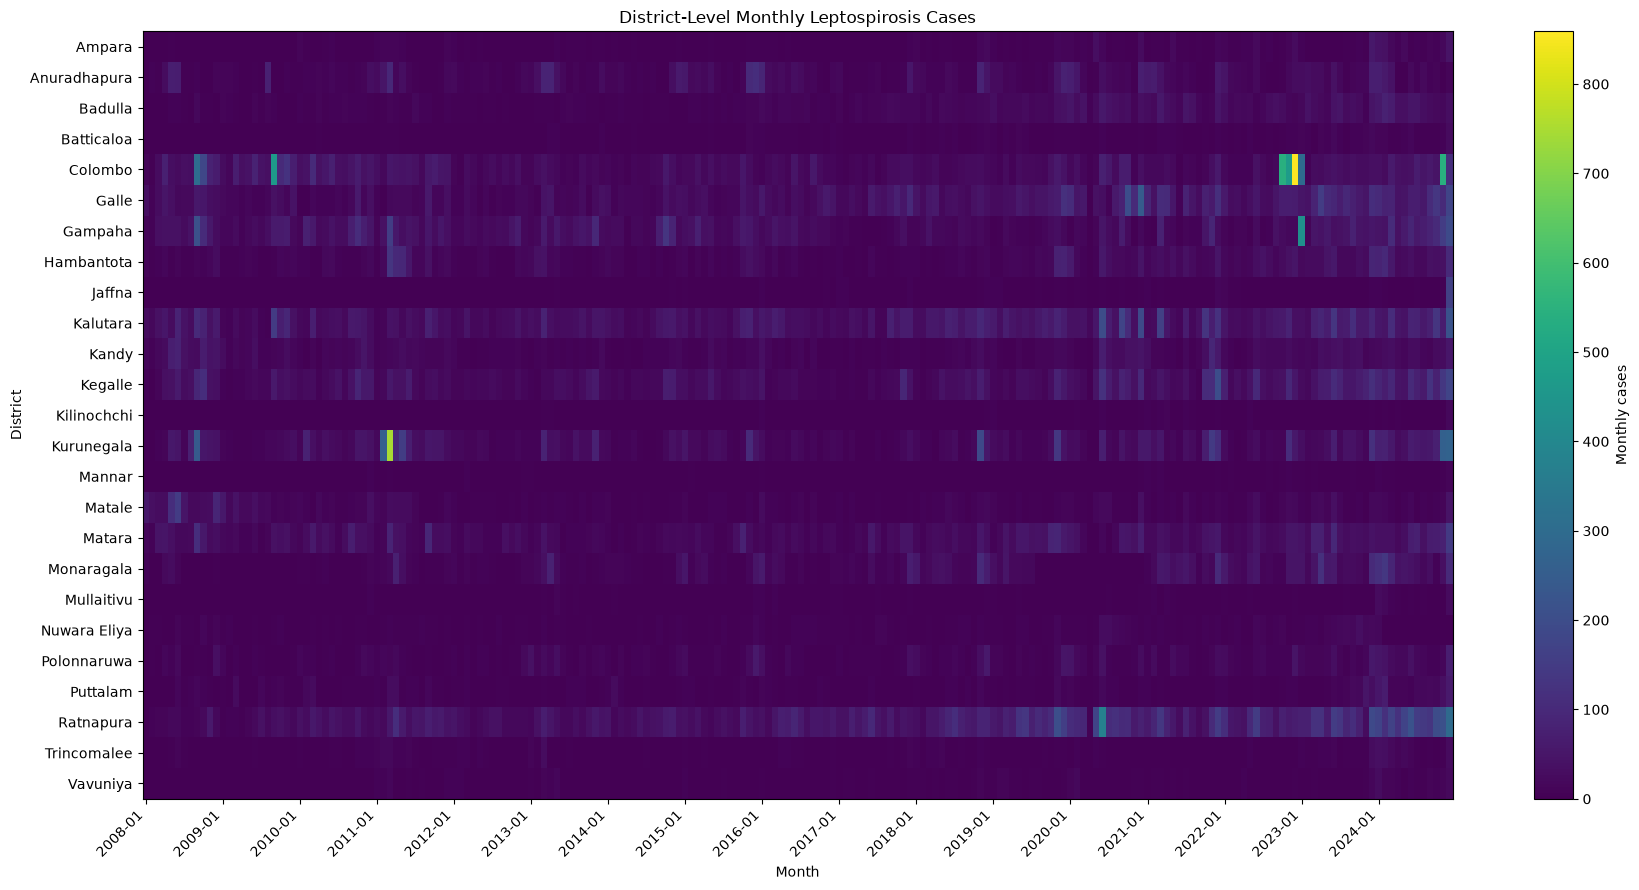

In [9]:

heatmap_data = df.pivot(
    index="District",
    columns="Date",
    values="Cases"
)

plt.figure(figsize=(18, 9))
plt.imshow(
    heatmap_data,
    aspect="auto",
    interpolation="nearest"
)
plt.colorbar(label="Monthly cases")
plt.title("District-Level Monthly Leptospirosis Cases")
plt.xlabel("Month")
plt.ylabel("District")

# Label selected dates to keep the plot readable
tick_positions = np.arange(0, len(heatmap_data.columns), 12)

plt.xticks(
    tick_positions,
    heatmap_data.columns[tick_positions].strftime("%Y-%m"),
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.tight_layout()
plt.show()


Explore relationships with climate variables

,Cases,Precipitation_mm,Temp_Min_C,Temp_Max_C,Soil_Moisture_0_7cm
Cases,1.000000,0.319009,-0.232970,-0.243976,0.457947
Precipitation_mm,0.319009,1.000000,-0.219870,-0.465267,0.721156
Temp_Min_C,-0.232970,-0.219870,1.000000,0.410172,-0.430587
Temp_Max_C,-0.243976,-0.465267,0.410172,1.000000,-0.610716
Soil_Moisture_0_7cm,0.457947,0.721156,-0.430587,-0.610716,1.000000


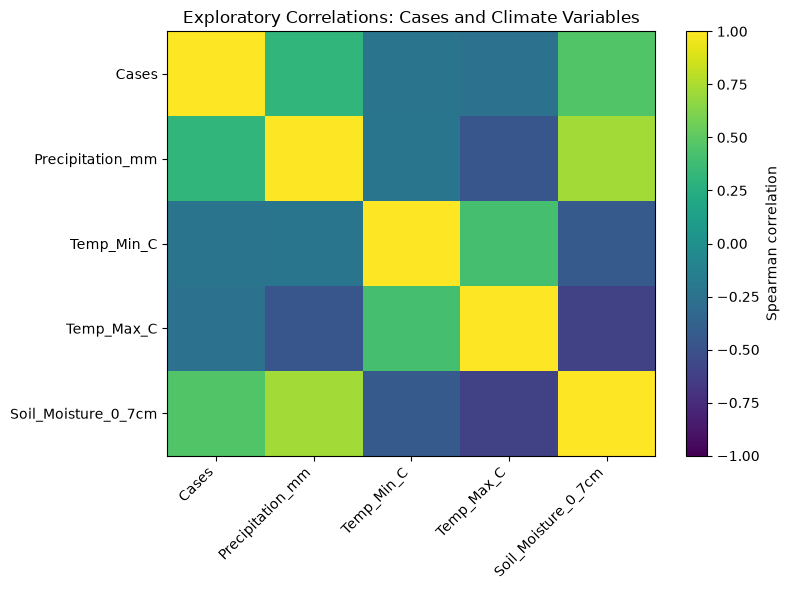

In [10]:

climate_columns = [
    "Precipitation_mm",
    "Temp_Min_C",
    "Temp_Max_C",
    "Soil_Moisture_0_7cm"
]

available_climate = [
    col for col in climate_columns if col in df.columns
]

correlation_data = df[["Cases"] + available_climate].copy()

correlation_matrix = correlation_data.corr(
    method="spearman",
    numeric_only=True
)

display(correlation_matrix)

plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Spearman correlation")
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)
plt.title("Exploratory Correlations: Cases and Climate Variables")
plt.tight_layout()
plt.show()


Save your EDA outputs

In [14]:

REPORT_DIR = Path("../../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

monthly_cases.to_csv(
    REPORT_DIR / "monthly_total_cases.csv",
    index=False
)

district_cases.to_csv(
    REPORT_DIR / "district_case_summary.csv",
    index=False
)

seasonal_cases.to_csv(
    REPORT_DIR / "seasonality_summary.csv",
    index=False
)

correlation_matrix.to_csv(
    REPORT_DIR / "climate_case_correlations.csv"
)

print("EDA summary files saved to:", REPORT_DIR.resolve())


EDA summary files saved to: D:\Research\Implementation\reports
